# 06 — WBC detection and unlabeled crops

**Purpose:** Predict on held-out microscopy images, save confidence-labeled boxes and optional WBC crops.

**Required inputs:** Completed best.pt; at least six held-out test images; optional custom image path.

**Saved outputs:** Timestamped `outputs/predictions/`, `outputs/wbc_crops/`, and `outputs/prediction_metadata.csv`.

## 1. Load the central configuration

The root is found from the notebook location or the installed package. Set `LEUKEMIA_YOLO_CONFIG` only for synthetic smoke tests or an alternate config.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "config.py").is_file():
        sys.path.insert(0, str(candidate))
        break
from src.config import load_config, ensure_outputs
cfg = load_config()
out = ensure_outputs(cfg)
os.chdir(cfg["root"])
print("Project root:", cfg["root"])
print("Configuration:", cfg["config_path"])

Project root: D:\CellCancer\leukemia-yolo
Configuration: D:\CellCancer\leukemia-yolo\config.local.yaml


## 2. Choose inference options

NMS uses the configured IoU threshold. Crops are WBC detections only; no Normal/Blast labels exist.

In [2]:
CUSTOM_IMAGE = None  # Optional Path to another microscope image.
CONFIDENCE = cfg["confidence"]
IOU_NMS = cfg["iou"]
CROP_WBCS = cfg["crop_wbcs"]
print("Confidence:", CONFIDENCE, "NMS IoU:", IOU_NMS, "Save crops:", CROP_WBCS)

Confidence: 0.25 NMS IoU: 0.7 Save crops: True


## 3. Predict at least six held-out examples

The shared function loads completed best.pt and records its SHA-256 in metadata.

In [3]:
from src.inference import predict
result = predict(cfg, custom=CUSTOM_IMAGE, limit=6, conf=CONFIDENCE, iou=IOU_NMS, crop=CROP_WBCS)
import pandas as pd
display(pd.DataFrame(result["examples"]))
print("Metadata:", result["metadata_csv"])
print("Crops:", result["crop_dir"])

,source,prediction,detected_wbcs
0,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1
1,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1
2,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1
3,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1
4,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1
5,D:\CellCancer\leukemia-yolo\data\processed\BCC...,D:\CellCancer\leukemia-yolo\outputs\prediction...,1


Metadata: D:\CellCancer\leukemia-yolo\outputs\predictions\predictions_20261013T090811Z_69d98a1c\prediction_metadata.csv
Crops: D:\CellCancer\leukemia-yolo\outputs\wbc_crops\predictions_20261013T090811Z_69d98a1c


## 4. Compare originals and detections

Confidence values and counts are shown with each saved prediction.

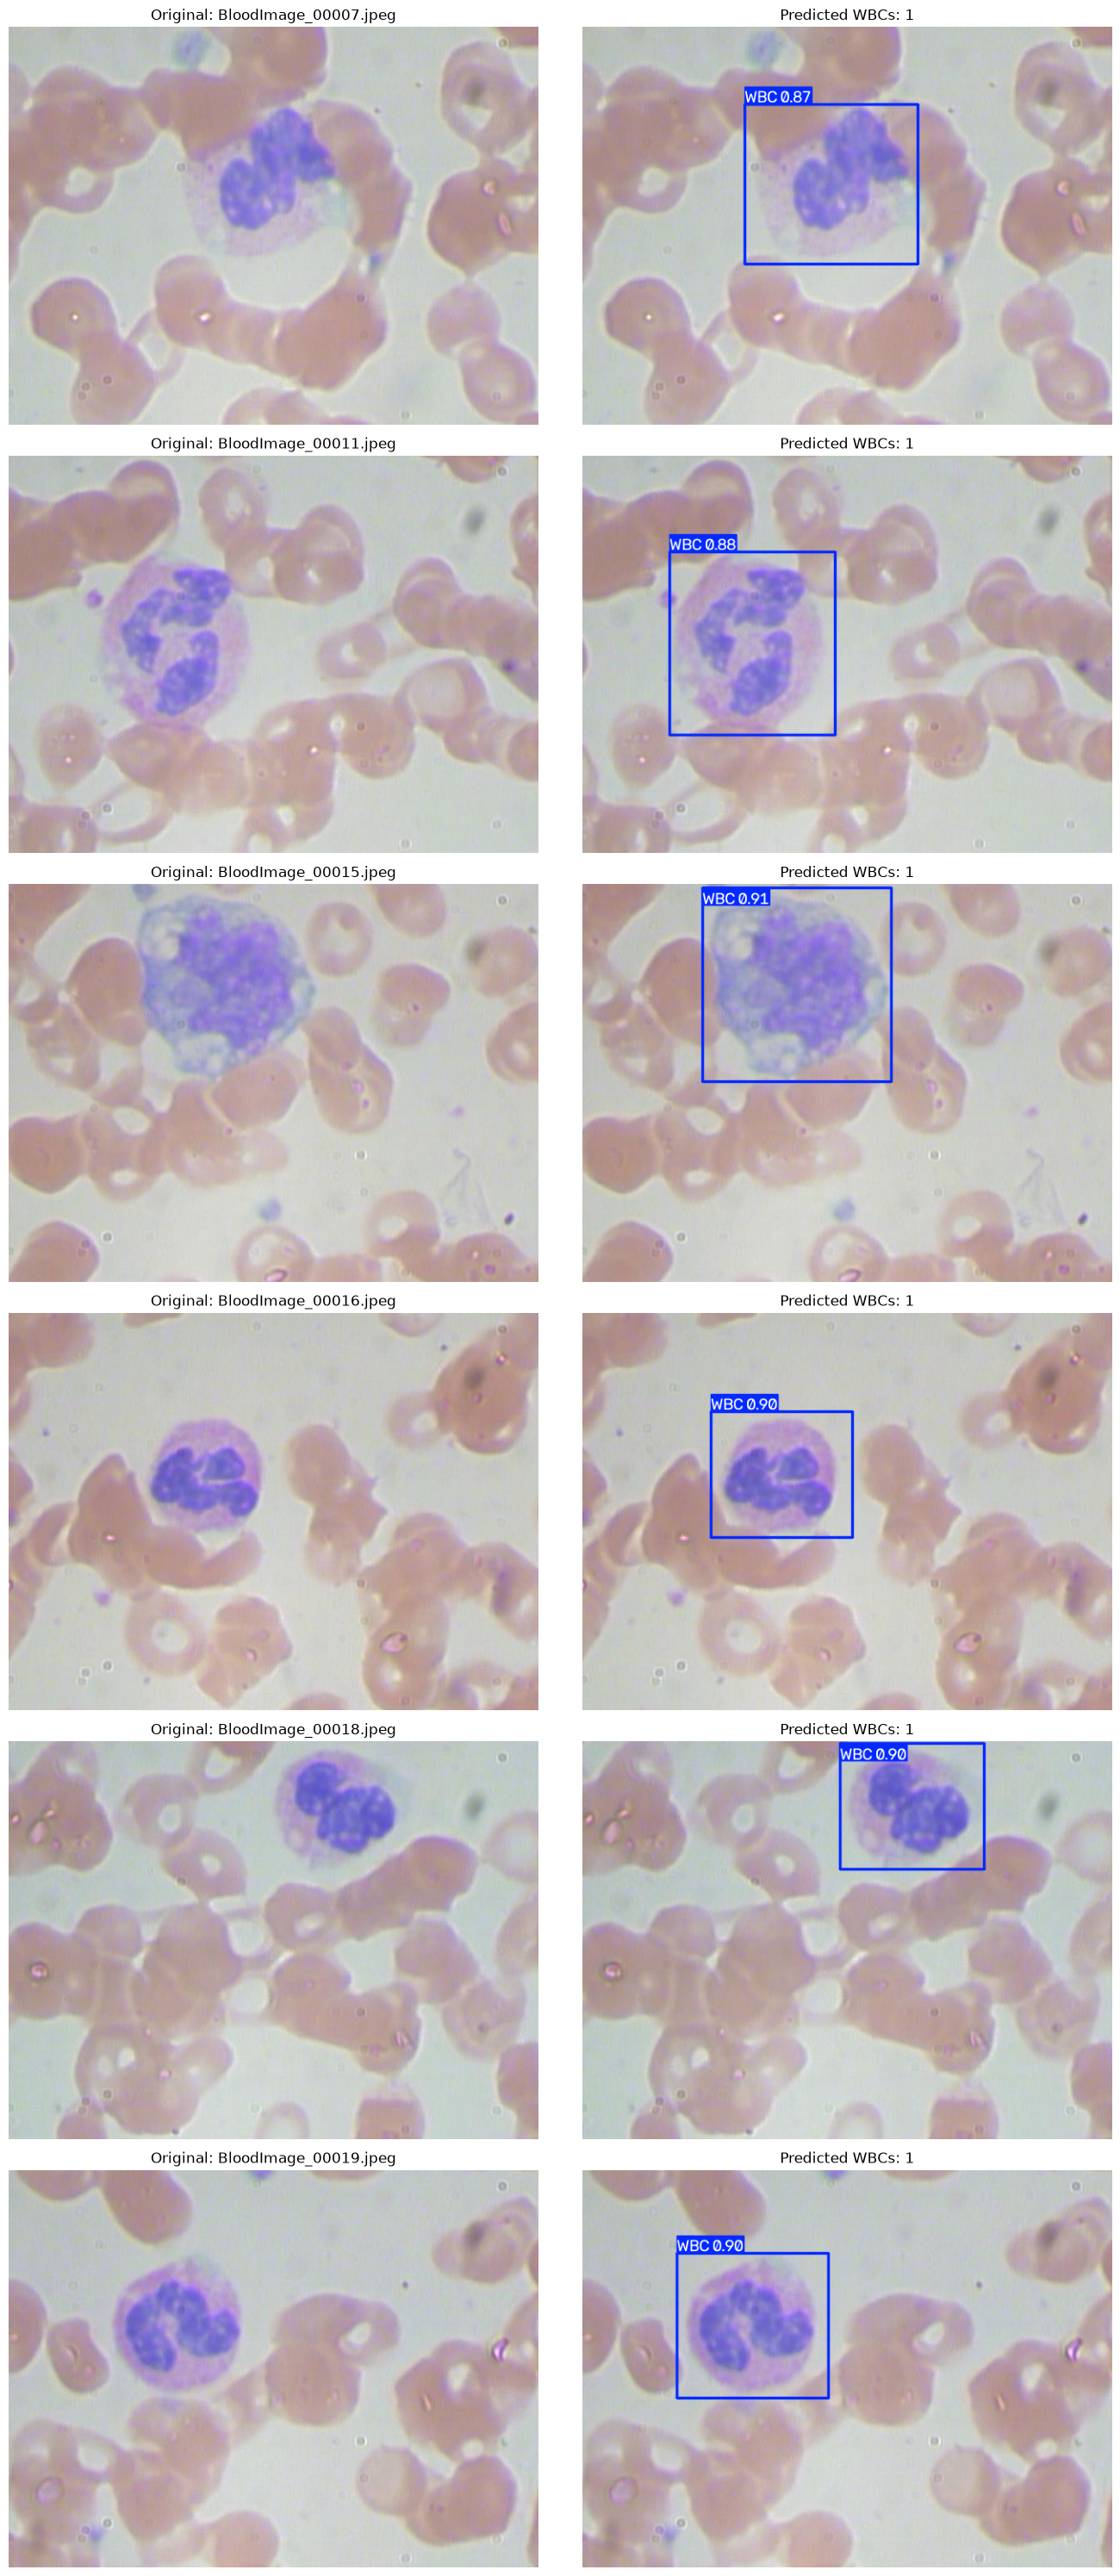

,source_image,xmin,ymin,xmax,ymax,confidence,crop_filename,model_checkpoint,checkpoint_sha256,confidence_threshold,iou_threshold
0,D:\CellCancer\leukemia-yolo\data\processed\BCC...,197,94,405,286,0.871227,000_BloodImage_00007_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7
1,D:\CellCancer\leukemia-yolo\data\processed\BCC...,106,116,305,337,0.884749,001_BloodImage_00011_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7
2,D:\CellCancer\leukemia-yolo\data\processed\BCC...,146,4,373,238,0.906439,002_BloodImage_00015_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7
3,D:\CellCancer\leukemia-yolo\data\processed\BCC...,156,119,326,272,0.898667,003_BloodImage_00016_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7
4,D:\CellCancer\leukemia-yolo\data\processed\BCC...,311,2,485,154,0.903144,004_BloodImage_00018_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7
5,D:\CellCancer\leukemia-yolo\data\processed\BCC...,115,100,298,276,0.895824,005_BloodImage_00019_wbc_000.png,D:\CellCancer\leukemia-yolo\outputs\checkpoint...,f75aed580dcc19a180600a727d896299a3e10e4e77b027...,0.25,0.7


In [4]:
import matplotlib.pyplot as plt
from PIL import Image
fig, axes = plt.subplots(len(result["examples"]), 2, figsize=(14, 5*len(result["examples"])))
for row, pair in zip(axes, result["examples"]):
    with Image.open(pair["source"]) as original, Image.open(pair["prediction"]) as pred:
        row[0].imshow(original.convert("RGB")); row[1].imshow(pred.convert("RGB"))
    row[0].set_title("Original: " + Path(pair["source"]).name)
    row[1].set_title(f"Predicted WBCs: {pair['detected_wbcs']}")
    for ax in row: ax.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)
metadata_rows = pd.read_csv(result["metadata_csv"])
display(metadata_rows.head(20))

## 5. Verify outputs

Every metadata row has coordinates, confidence, threshold, crop filename and model identity.

In [5]:
assert len(result["examples"]) >= 6
assert Path(result["metadata_csv"]).is_file()
print("PASS — WBC detection artifacts saved. Next: notebook 07.")

PASS — WBC detection artifacts saved. Next: notebook 07.


## Next notebook

Open **07_Conference_Results.ipynb**.